# 📘 5.3 Support Vector Regression

### Learning smooth engineering relationships with margins and kernels

Linear regression fits one global equation. A decision tree creates flat,
threshold-based regions. **Support Vector Regression (SVR)** offers another approach:
it can fit a smooth nonlinear relationship while allowing a chosen band of small errors.

SVR can be effective for moderate datasets and nonlinear responses. Its flexibility
makes feature scaling, hyperparameter selection, validation and domain checks essential.
A smooth curve is not evidence that a model obeys physics outside measured conditions.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* explain the epsilon-insensitive idea and identify support vectors;
* build a `Pipeline` containing `StandardScaler` and `SVR`;
* compare linear and radial-basis-function kernels;
* investigate how `C`, `epsilon` and `gamma` change model behaviour;
* select hyperparameters using validation evidence;
* explain why feature scaling matters for distance-based kernels; and
* recognise unsupported extrapolation and other engineering limitations.

### 🔗 Unit Learning Outcome Alignment

This notebook supports **LO1, LO2 and LO3** through method selection, executable
modelling, validation, error interpretation and limitations.

### 📚 Sources used in this notebook

* scikit-learn — [SVR](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html)
* scikit-learn — [Support Vector Machines user guide](https://scikit-learn.org/stable/modules/svm.html)
* scikit-learn — [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
* scikit-learn — [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
* NASA Glenn Research Center — [The Drag Equation](https://www.grc.nasa.gov/www/k-12/VirtualAero/BottleRocket/airplane/drageq.html)


## 📂 5.3.0 How to use this notebook

This is a **pre-work content notebook**. Run every code cell from top to bottom; no cell
requires editing or typed input. The optional slider has a static fallback.

The Week 5 workbook will provide a guided parameter exploration and a related problem
to solve with all required imports and helper functions supplied.


## 📂 5.3.1 The epsilon-insensitive idea

A regression model draws a prediction curve through a cloud of measured data. If we
demanded that the curve pass as close as possible to every measurement, it could react
to small measurement noise instead of learning the underlying relationship.

SVR therefore lets us define an **acceptable vertical error band** around its prediction
curve. This band is called the **epsilon tube**:

* the centre of the tube is the prediction $f(\mathbf{x})$;
* its upper boundary is $f(\mathbf{x})+\epsilon$;
* its lower boundary is $f(\mathbf{x})-\epsilon$; and
* its total vertical width is $2\epsilon$ in the units of the target.

The word *tube* describes the shape formed by these two boundaries as they follow the
prediction curve across the feature domain. It is a tolerance band in a graph, not a
physical tube and not a feature-range boundary.

For example, if predicted drag is $100\ \mathrm{N}$ and $\epsilon=4\ \mathrm{N}$, the
tube extends from $96\ \mathrm{N}$ to $104\ \mathrm{N}$ at that airspeed. A measured
value of $102\ \mathrm{N}$ lies inside it. A measured value of $107\ \mathrm{N}$ lies
$3\ \mathrm{N}$ beyond it.

During fitting, deviations inside the tube receive zero epsilon-insensitive loss. Only
the part of an error extending beyond the tube is counted:

$$L_\epsilon(y,f(\mathbf{x}))=\max(0,|y-f(\mathbf{x})|-\epsilon).$$

This allows the optimisation to focus on finding a suitably simple prediction function
rather than chasing every small deviation. Samples on or outside the tube commonly
become **support vectors** and determine the fitted curve; samples comfortably inside
usually do not pull the curve toward themselves.

This does not mean that errors inside the tube are physically harmless. The choice of
$\epsilon$ must be justified using the target's units, measurement behaviour and
engineering consequences. The epsilon tube is not a confidence interval, prediction
interval or safety limit.


### 📖 Core language for 5.3

* A **kernel** measures similarity between feature vectors.
* The **RBF kernel** allows a smooth nonlinear prediction without explicitly adding
  polynomial columns.
* A **support vector** is a training sample retained in the fitted SVR solution.
* `C` controls the trade-off between a flatter model and errors beyond the tube.
* `epsilon` sets the tube half-width in target units.
* `gamma` controls how local the influence of an RBF support vector is.
* **Scaling** puts features on comparable numerical scales before evaluating the kernel.


In [ ]:
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

pd.set_option("display.precision", 4)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


## 📂 5.3.2 Engineering example: aerodynamic drag

NASA gives the drag equation as

$$D=\frac{1}{2}\rho C_D A V^2,$$

where $D$ is drag force, $\rho$ is fluid density, $C_D$ is drag coefficient, $A$ is
reference area and $V$ is relative speed. With the other quantities fixed, drag rises
with the square of speed.

### ⚠️ Data note

The dataset is **synthetic and deterministic**. It represents noisy wind-tunnel-style
measurements for one fixed configuration. The constants are selected for teaching and
are not certified properties of a particular object. In a real experiment, the
noise-free force would not be available.


In [ ]:
rng = np.random.default_rng(5301)
air_density_kgm3 = 1.225
drag_coefficient = 0.82
reference_area_m2 = 0.18

speed_ms = np.linspace(5.0, 45.0, 55)
true_drag_n = 0.5 * air_density_kgm3 * drag_coefficient * reference_area_m2 * speed_ms**2
measured_drag_n = true_drag_n + rng.normal(0.0, 2.5, speed_ms.size)

drag_data = pd.DataFrame({
    "speed_ms": speed_ms,
    "measured_drag_n": measured_drag_n,
    "true_drag_for_teaching_only_n": true_drag_n,
})
drag_data.head(8)


,speed_ms,measured_drag_n,true_drag_for_teaching_only_n
0,5.0000,0.4462,2.2601
1,5.7407,2.2994,2.9794
2,6.4815,7.7546,3.7979
3,7.2222,7.1709,4.7156
4,7.9630,0.7995,5.7325
5,8.7037,7.2363,6.8486
6,9.4444,7.4371,8.0639
7,10.1852,8.2164,9.3784


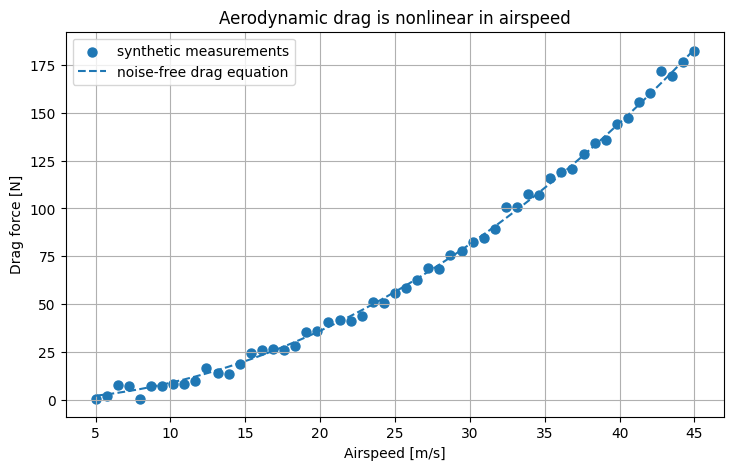

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(drag_data["speed_ms"], drag_data["measured_drag_n"], s=42,
           label="synthetic measurements")
ax.plot(drag_data["speed_ms"], drag_data["true_drag_for_teaching_only_n"], "--",
        label="noise-free drag equation")
ax.set(xlabel="Airspeed [m/s]", ylabel="Drag force [N]",
       title="Aerodynamic drag is nonlinear in airspeed")
ax.grid(True); ax.legend(); plt.show()


### 🧠 What should you notice?

The response is smooth and curved rather than piecewise constant. We already know a
plausible governing equation here. In real engineering work, machine learning should
not replace reliable physics without a clear need; it is valuable when dependencies are
unknown, too complex, or expensive to calculate directly.


## 📂 5.3.3 Training and validation data

We reserve unseen samples for model comparison. The target remains in newtons, so
`epsilon` will also be interpreted in newtons.


In [ ]:
X = drag_data[["speed_ms"]]
y = drag_data["measured_drag_n"]
X_train, X_validation, y_train, y_validation = train_test_split(
    X, y, test_size=0.27, random_state=42
)

pd.DataFrame({
    "subset": ["training", "validation"],
    "samples": [len(X_train), len(X_validation)],
    "minimum_speed_ms": [X_train.speed_ms.min(), X_validation.speed_ms.min()],
    "maximum_speed_ms": [X_train.speed_ms.max(), X_validation.speed_ms.max()],
})


,subset,samples,minimum_speed_ms,maximum_speed_ms
0,training,40,5.0000,45.0000
1,validation,15,7.2222,43.5185


## 📂 5.3.4 Build scaling into the model pipeline

The RBF kernel is based on distances. `StandardScaler` subtracts the training mean and
divides by the training standard deviation. Inside a `Pipeline`, scaling is learned from
training data and applied identically during prediction. Only features are scaled here;
predicted drag remains in newtons.


In [ ]:
rbf_svr = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=100.0, epsilon=4.0, gamma=0.3),
)
rbf_svr.fit(X_train, y_train)
pd.Series(metrics(y_validation, rbf_svr.predict(X_validation)),
          name="RBF SVR validation performance")


,RBF SVR validation performance
MAE,1.5273
RMSE,2.1524
R2,0.9983


### 🔍 Reading the pipeline

`fit` learns the scaler from `X_train`, transforms the speeds and fits SVR. `predict`
applies the stored transformation automatically. This also reduces data leakage: the
validation values are not used to calculate the training mean or standard deviation.


## 📂 5.3.5 Linear and RBF kernels

A linear kernel restricts SVR to a straight relationship in the supplied features. An
RBF kernel can represent a smooth nonlinear relationship. Both models below receive
only airspeed; we have not supplied `speed_ms**2`.


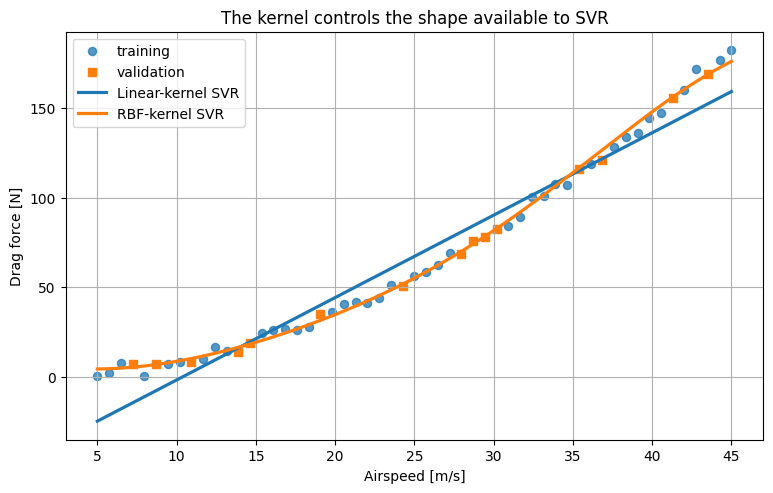

,MAE,RMSE,R2
model,,,
Linear-kernel SVR,8.9537,10.8899,0.9567
RBF-kernel SVR,1.5273,2.1524,0.9983


In [ ]:
kernel_models = {
    "Linear-kernel SVR": make_pipeline(StandardScaler(),
        SVR(kernel="linear", C=100.0, epsilon=4.0)),
    "RBF-kernel SVR": make_pipeline(StandardScaler(),
        SVR(kernel="rbf", C=100.0, epsilon=4.0, gamma=0.3)),
}
speed_grid = pd.DataFrame({"speed_ms": np.linspace(5.0, 45.0, 400)})
rows = []
fig, ax = plt.subplots(figsize=(9, 5.3))
ax.scatter(X_train.speed_ms, y_train, s=34, alpha=0.75, label="training")
ax.scatter(X_validation.speed_ms, y_validation, marker="s", s=40, label="validation")
for label, model in kernel_models.items():
    model.fit(X_train, y_train)
    rows.append({"model": label, **metrics(y_validation, model.predict(X_validation))})
    ax.plot(speed_grid.speed_ms, model.predict(speed_grid), linewidth=2.3, label=label)
ax.set(xlabel="Airspeed [m/s]", ylabel="Drag force [N]",
       title="The kernel controls the shape available to SVR")
ax.grid(True); ax.legend(); plt.show()
pd.DataFrame(rows).set_index("model")


### 🧠 What does the RBF kernel do?

$$K(\mathbf{x},\mathbf{x}')=\exp(-\gamma\lVert\mathbf{x}-\mathbf{x}'\rVert^2).$$

Nearby scaled feature vectors have high similarity. The prediction combines the
influence of support vectors, while `gamma` determines how quickly similarity falls
with distance. The RBF model captures curvature more effectively here, but kernel choice
still requires validation evidence and engineering judgement.


## 📂 5.3.6 Support vectors and the epsilon tube

`support_` contains row positions from the data passed to `fit`. We can recover those
samples and draw the epsilon tube in target units.


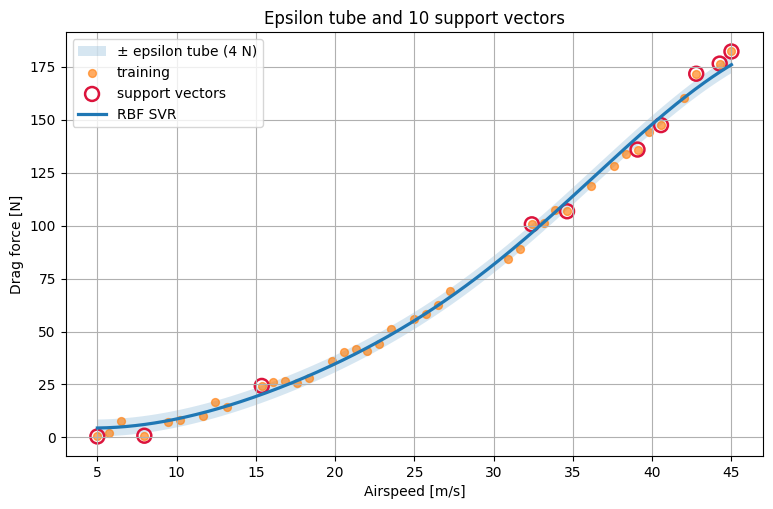

In [ ]:
fitted_svr = rbf_svr.named_steps["svr"]
support_positions = fitted_svr.support_
support_speeds = X_train.iloc[support_positions].speed_ms
support_targets = y_train.iloc[support_positions]
grid_prediction = rbf_svr.predict(speed_grid)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.fill_between(speed_grid.speed_ms, grid_prediction - fitted_svr.epsilon,
                grid_prediction + fitted_svr.epsilon, alpha=0.18,
                label=f"± epsilon tube ({fitted_svr.epsilon:g} N)")
ax.scatter(X_train.speed_ms, y_train, s=32, alpha=0.65, label="training")
ax.scatter(support_speeds, support_targets, s=100, facecolors="none",
           edgecolors="crimson", linewidths=1.8, label="support vectors")
ax.plot(speed_grid.speed_ms, grid_prediction, linewidth=2.3, label="RBF SVR")
ax.set(xlabel="Airspeed [m/s]", ylabel="Drag force [N]",
       title=f"Epsilon tube and {len(support_positions)} support vectors")
ax.grid(True); ax.legend(); plt.show()


### ⚠️ Point of note

A support vector is not necessarily an outlier or a physically important experiment.
A wider tube will usually retain fewer support vectors and accept larger deviations.
The tube is not a confidence interval or probability statement.


## 📂 5.3.7 What do `C`, `epsilon` and `gamma` change?

* Small `C` permits more deviation beyond the tube; large `C` tries harder to fit data.
* Larger `epsilon` creates a wider no-penalty tube in target units.
* Small `gamma` gives broad influence; large `gamma` creates very local influence.

The next three galleries isolate these effects while holding the others fixed.


In [ ]:
def parameter_gallery(parameter, values, fixed):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
    for ax, value in zip(axes, values):
        settings = fixed | {parameter: value}
        model = make_pipeline(StandardScaler(), SVR(kernel="rbf", **settings))
        model.fit(X_train, y_train)
        score = rmse(y_validation, model.predict(X_validation))
        support_count = model.named_steps["svr"].n_support_[0]
        ax.scatter(X_train.speed_ms, y_train, s=24, alpha=0.65)
        ax.plot(speed_grid.speed_ms, model.predict(speed_grid), linewidth=2.2)
        unit = " N" if parameter == "epsilon" else ""
        ax.set_title(f"{parameter} = {value:g}{unit}\nRMSE = {score:.2f} N; SV = {support_count}")
        ax.set_xlabel("Airspeed [m/s]"); ax.grid(True)
    axes[0].set_ylabel("Drag force [N]")
    fig.suptitle(f"Effect of {parameter}")
    fig.tight_layout(); plt.show()


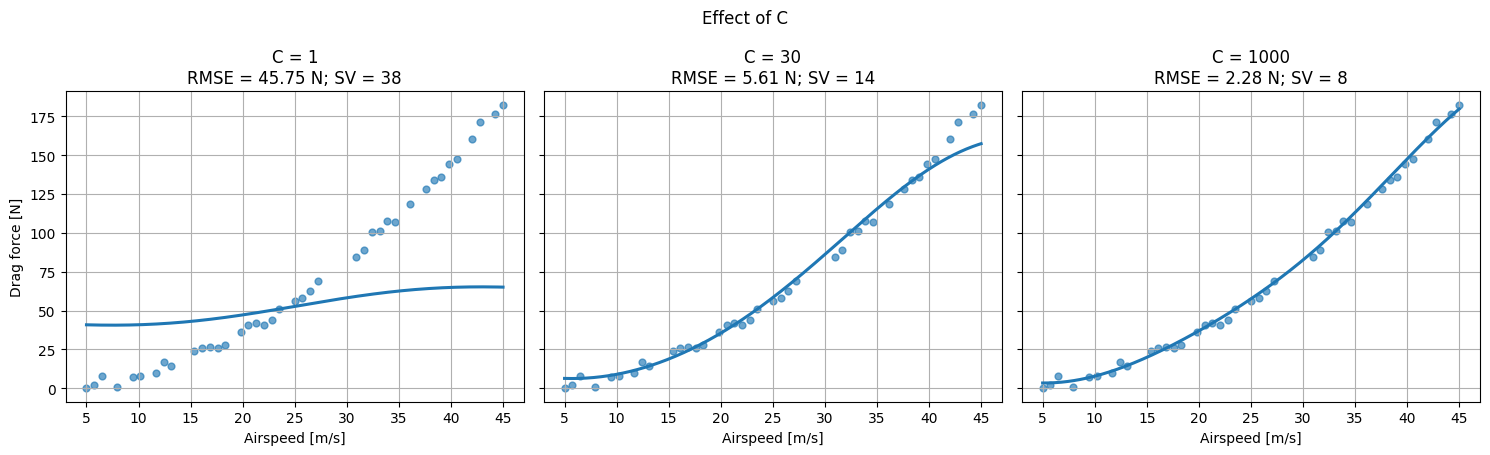

In [ ]:
parameter_gallery("C", [1.0, 30.0, 1000.0],
                  {"C": 100.0, "epsilon": 4.0, "gamma": 0.3})


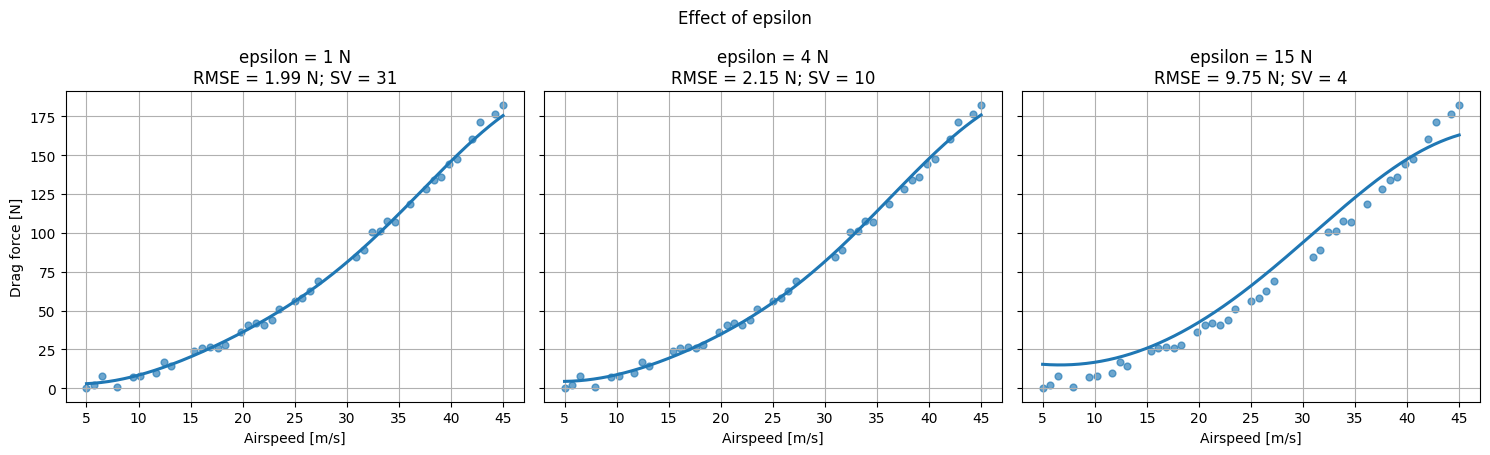

In [ ]:
parameter_gallery("epsilon", [1.0, 4.0, 15.0],
                  {"C": 100.0, "epsilon": 4.0, "gamma": 0.3})


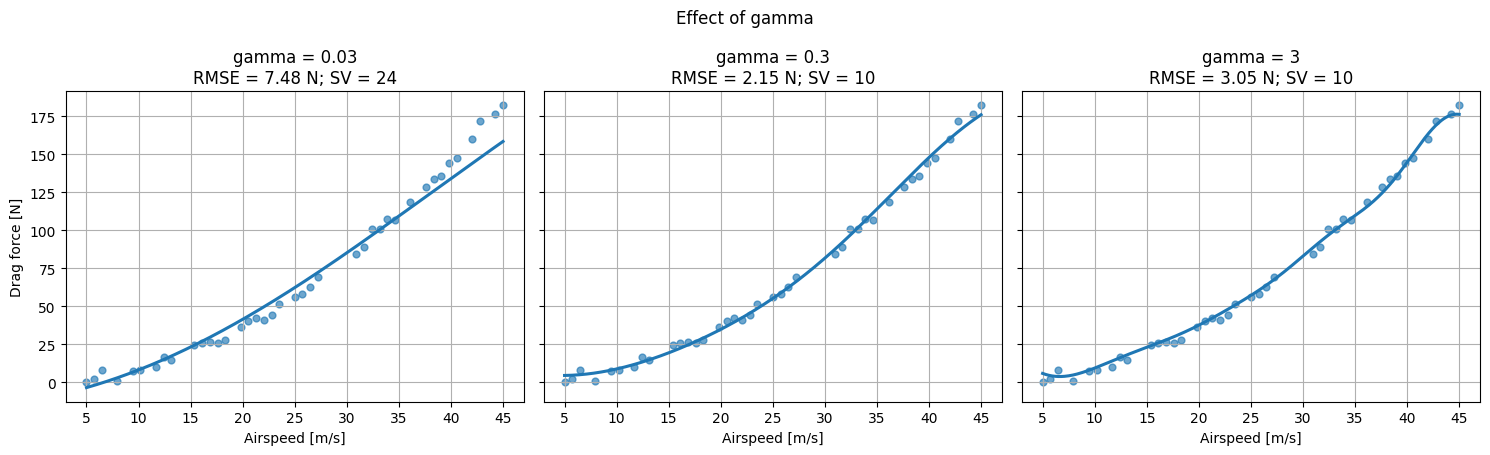

In [ ]:
parameter_gallery("gamma", [0.03, 0.3, 3.0],
                  {"C": 100.0, "epsilon": 4.0, "gamma": 0.3})


### 🧩 Hyperparameters interact

A very local kernel combined with a large penalty can fit noise, while a broad kernel
and small penalty may underfit curvature. One-at-a-time plots build intuition; final
selection must compare combinations using validation evidence.


## 📂 5.3.8 Compare parameter combinations

We use a small transparent search. Every candidate is fitted only on training data and
scored on the same held-out validation set. Repeated reuse of a validation set can itself
cause overfitting; Notebook 5.5 develops cross-validation and final-test roles.


In [ ]:
search_rows = []
for C in [10.0, 100.0, 1000.0]:
    for epsilon in [1.0, 4.0, 8.0]:
        for gamma in [0.03, 0.1, 0.3, 1.0]:
            model = make_pipeline(StandardScaler(),
                SVR(kernel="rbf", C=C, epsilon=epsilon, gamma=gamma))
            model.fit(X_train, y_train)
            search_rows.append({
                "C": C, "epsilon_N": epsilon, "gamma": gamma,
                "validation_RMSE_N": rmse(y_validation, model.predict(X_validation)),
                "support_vectors": model.named_steps["svr"].n_support_[0],
            })
search_results = pd.DataFrame(search_rows).sort_values("validation_RMSE_N")
search_results.head(10)


,C,epsilon_N,gamma,validation_RMSE_N,support_vectors
14,100.0,1.0,0.30,1.9896,31
25,1000.0,1.0,0.10,2.0310,29
26,1000.0,1.0,0.30,2.0777,26
18,100.0,4.0,0.30,2.1524,10
29,1000.0,4.0,0.10,2.1881,7
15,100.0,1.0,1.00,2.2086,32
24,1000.0,1.0,0.03,2.2372,31
30,1000.0,4.0,0.30,2.2831,8
27,1000.0,1.0,1.00,2.4417,31
28,1000.0,4.0,0.03,2.4732,7


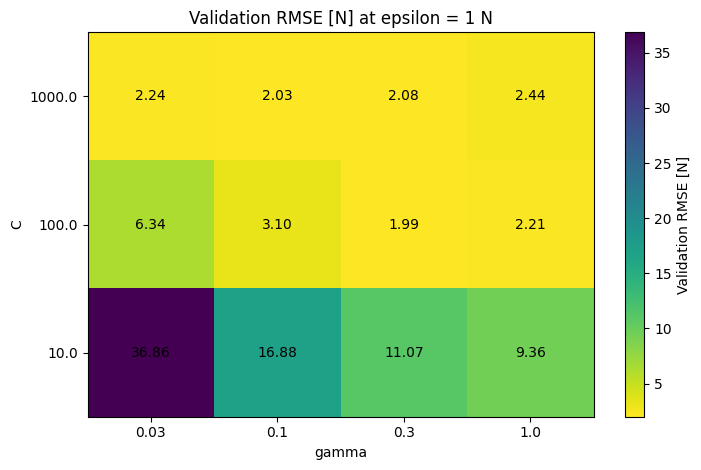

,selected value
C,100.0000
epsilon_N,1.0000
gamma,0.3000
validation_RMSE_N,1.9896
support_vectors,31.0000


In [ ]:
best = search_results.iloc[0]
best_svr = make_pipeline(StandardScaler(), SVR(
    kernel="rbf", C=best.C, epsilon=best.epsilon_N, gamma=best.gamma))
best_svr.fit(X_train, y_train)

table = (search_results[search_results.epsilon_N == best.epsilon_N]
         .pivot(index="C", columns="gamma", values="validation_RMSE_N")
         .sort_index(ascending=False))
fig, ax = plt.subplots(figsize=(7.4, 4.8))
image = ax.imshow(table, cmap="viridis_r", aspect="auto")
ax.set_xticks(range(len(table.columns)), table.columns)
ax.set_yticks(range(len(table.index)), table.index)
ax.set(xlabel="gamma", ylabel="C",
       title=f"Validation RMSE [N] at epsilon = {best.epsilon_N:g} N")
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        ax.text(j, i, f"{table.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Validation RMSE [N]")
fig.tight_layout(); plt.show()
best.to_frame(name="selected value")


### ⚠️ Selection is not proof

The smallest displayed RMSE identifies the best candidate **among this limited search on
this split**. It is not a universal optimum or an uncertainty estimate. Report chosen
values with the validation strategy, target units and data coverage.


## 📂 5.3.9 Optional interactive gamma demonstration

Move the slider to change RBF locality while `C` and `epsilon` remain fixed. A static
example appears if widgets are unavailable.


In [ ]:
def plot_gamma_effect(gamma=0.3):
    model = make_pipeline(StandardScaler(),
        SVR(kernel="rbf", C=100.0, epsilon=4.0, gamma=gamma))
    model.fit(X_train, y_train)
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    ax.scatter(X_train.speed_ms, y_train, s=32, alpha=0.7, label="training")
    ax.plot(speed_grid.speed_ms, model.predict(speed_grid), linewidth=2.3, label="RBF SVR")
    ax.set(xlabel="Airspeed [m/s]", ylabel="Drag force [N]",
           title=f"gamma = {gamma:.3f}; support vectors = {model.named_steps['svr'].n_support_[0]}")
    ax.grid(True); ax.legend(); plt.show()
try:
    from ipywidgets import FloatLogSlider, interact
    interact(plot_gamma_effect, gamma=FloatLogSlider(
        value=0.3, base=10, min=-2, max=1, step=0.1,
        description="gamma", continuous_update=False))
except ImportError:
    print("ipywidgets is unavailable; showing gamma = 0.3.")
    plot_gamma_effect(0.3)


interactive(children=(FloatLogSlider(value=0.3, continuous_update=False, description='gamma', max=1.0, min=-2.…

## 📂 5.3.10 Extrapolation outside the training domain

Far from observed data, RBF similarities become small. The result is not a continuation
of the physical drag trend. The known teaching equation makes this visible; in a real
data-only problem unsupported behaviour might be less obvious.


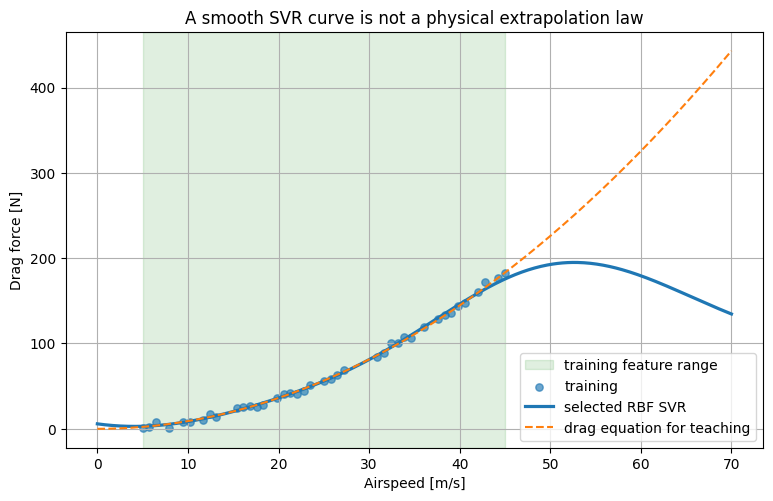

In [ ]:
extended = pd.DataFrame({"speed_ms": np.linspace(0.0, 70.0, 500)})
extended_truth = (0.5 * air_density_kgm3 * drag_coefficient * reference_area_m2
                  * extended.speed_ms.to_numpy()**2)
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.axvspan(X_train.speed_ms.min(), X_train.speed_ms.max(), alpha=0.12,
           color="green", label="training feature range")
ax.scatter(X_train.speed_ms, y_train, s=28, alpha=0.65, label="training")
ax.plot(extended.speed_ms, best_svr.predict(extended), linewidth=2.3,
        label="selected RBF SVR")
ax.plot(extended.speed_ms, extended_truth, "--", label="drag equation for teaching")
ax.set(xlabel="Airspeed [m/s]", ylabel="Drag force [N]",
       title="A smooth SVR curve is not a physical extrapolation law")
ax.grid(True); ax.legend(); plt.show()


In [ ]:
def predict_with_range_check(model, query, training_features):
    result = query.copy()
    result["prediction_n"] = model.predict(query)
    result["inside_training_box"] = (
        query.ge(training_features.min()).all(axis=1)
        & query.le(training_features.max()).all(axis=1)
    )
    return result

predict_with_range_check(best_svr,
    pd.DataFrame({"speed_ms": [12.0, 35.0, 52.0, 65.0]}), X_train)


,speed_ms,prediction_n,inside_training_box
0,12.0,12.5726,True
1,35.0,112.2542,True
2,52.0,194.8422,False
3,65.0,157.3955,False


### ⚠️ Range checks are necessary but incomplete

With several features, a point can lie inside every individual range but still be far
from all observed combinations. Physical regimes, equipment identity and distribution
shift may also matter. An unflagged prediction is not automatically well supported.


## 📂 5.3.11 Why scaling matters with multiple features

We now vary airspeed and air density. Speed is measured in tens, while density varies by
a fraction. Unscaled distances can be dominated by the numerically larger feature. The
dataset uses the same teaching equation plus measurement noise.


In [ ]:
rng_2d = np.random.default_rng(5302)
n_2d = 180
speed_2d = rng_2d.uniform(5.0, 45.0, n_2d)
density_2d = rng_2d.uniform(0.85, 1.35, n_2d)
truth_2d = 0.5 * density_2d * drag_coefficient * reference_area_m2 * speed_2d**2
target_2d = truth_2d + rng_2d.normal(0.0, 3.0, n_2d)

X2 = pd.DataFrame({"speed_ms": speed_2d, "air_density_kgm3": density_2d})
y2 = pd.Series(target_2d, name="measured_drag_n")
X2_train, X2_validation, y2_train, y2_validation = train_test_split(
    X2, y2, test_size=0.25, random_state=42)
X2_train.describe().loc[["mean", "std", "min", "max"]]


,speed_ms,air_density_kgm3
mean,24.4999,1.1134
std,12.0071,0.1332
min,5.1215,0.8640
max,44.7007,1.3459


In [ ]:
scaling_models = {
    "Unscaled RBF SVR": SVR(kernel="rbf", C=100.0, epsilon=3.0, gamma="scale"),
    "Scaled RBF SVR": make_pipeline(StandardScaler(),
        SVR(kernel="rbf", C=100.0, epsilon=3.0, gamma="scale")),
}
scaling_rows = []
for label, model in scaling_models.items():
    model.fit(X2_train, y2_train)
    scaling_rows.append({"model": label,
                         **metrics(y2_validation, model.predict(X2_validation))})
pd.DataFrame(scaling_rows).set_index("model")


,MAE,RMSE,R2
model,,,
Unscaled RBF SVR,7.2672,9.6525,0.9537
Scaled RBF SVR,2.8206,3.5895,0.9936


### 🧠 Interpretation

`gamma="scale"` adapts to overall variance but does not standardise each feature. The
pipeline allows density differences to contribute meaningfully to RBF distances.
Scaling does not make a feature physically important; it prevents units from deciding
influence before fitting.


## 📂 5.3.12 Visualising the two-feature prediction surface

We compare the scaled SVR with the teaching equation and show their absolute difference
inside the sampled feature ranges.


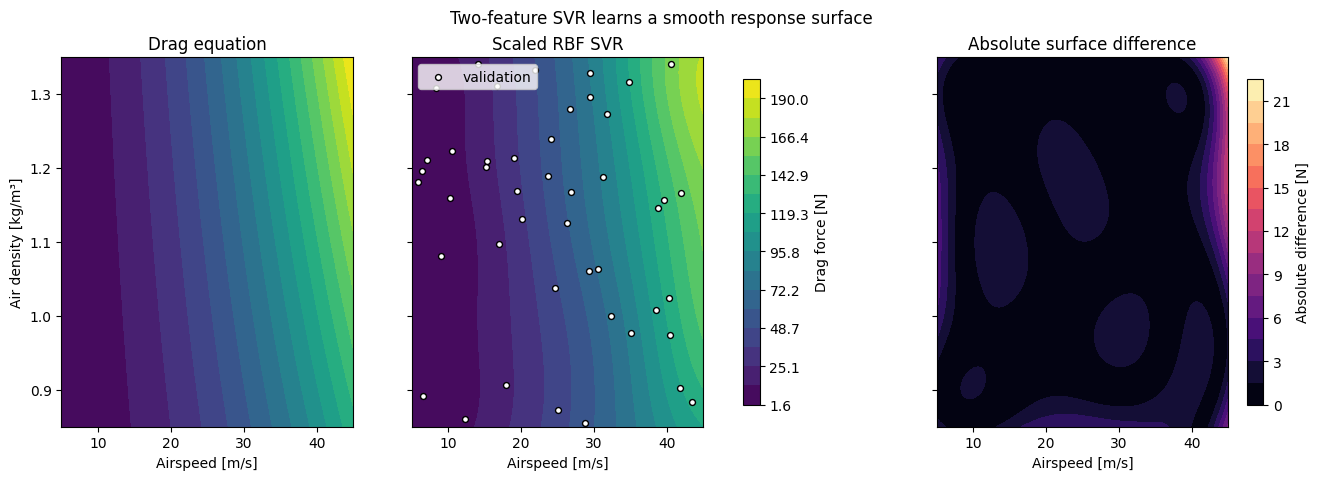

In [ ]:
scaled_svr_2d = scaling_models["Scaled RBF SVR"]
speed_axis = np.linspace(5.0, 45.0, 150)
density_axis = np.linspace(0.85, 1.35, 150)
speed_surface, density_surface = np.meshgrid(speed_axis, density_axis)
queries = pd.DataFrame({"speed_ms": speed_surface.ravel(),
                        "air_density_kgm3": density_surface.ravel()})
prediction_surface = scaled_svr_2d.predict(queries).reshape(speed_surface.shape)
truth_surface = (0.5 * density_surface * drag_coefficient * reference_area_m2
                 * speed_surface**2)
difference_surface = np.abs(prediction_surface - truth_surface)
force_levels = np.linspace(min(truth_surface.min(), prediction_surface.min()),
                           max(truth_surface.max(), prediction_surface.max()), 18)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
axes[0].contourf(speed_surface, density_surface, truth_surface,
                 levels=force_levels, cmap="viridis")
force_map = axes[1].contourf(speed_surface, density_surface, prediction_surface,
                            levels=force_levels, cmap="viridis")
error_map = axes[2].contourf(speed_surface, density_surface, difference_surface,
                            levels=15, cmap="magma")
axes[0].set_title("Drag equation"); axes[1].set_title("Scaled RBF SVR")
axes[2].set_title("Absolute surface difference")
axes[1].scatter(X2_validation.speed_ms, X2_validation.air_density_kgm3,
                c="white", edgecolor="black", s=18, label="validation")
axes[1].legend(loc="upper left")
for ax in axes: ax.set_xlabel("Airspeed [m/s]")
axes[0].set_ylabel("Air density [kg/m³]")
fig.colorbar(force_map, ax=axes[:2], shrink=0.88, label="Drag force [N]")
fig.colorbar(error_map, ax=axes[2], shrink=0.88, label="Absolute difference [N]")
fig.suptitle("Two-feature SVR learns a smooth response surface")
plt.show()


### 🧠 What should you notice?

The fitted surface captures the dominant speed effect and smaller density effect, but
error is not uniform. A single metric should be accompanied by location-aware plots.
Exact comparison is possible only because this example is synthetic.


## 📂 5.3.13 Method limitations and engineering checks

Before using SVR, ask:

1. Is the dataset moderate enough for standard `SVR` fitting?
2. Were preprocessing steps fitted only on training data?
3. Are feature and target units documented, and is `epsilon` meaningful in those units?
4. Were kernel, `C`, `epsilon` and `gamma` selected using validation evidence?
5. Does the model outperform a baseline across the intended domain?
6. Are queries supported by relevant training combinations?
7. Is a physics-based model available and more defensible?
8. Have smooth predictions been kept separate from uncertainty claims?

Standard SVR does not automatically provide prediction intervals, causal explanations or
physically valid extrapolation. Its fitting cost grows rapidly with sample count.


## 📂 5.3.14 Useful packages and functions

| Package | Function or parameter | Purpose | Important caution |
|---|---|---|---|
| `sklearn.svm` | `SVR` | Fit epsilon-support vector regression | Costly for very large datasets |
| `sklearn.preprocessing` | `StandardScaler` | Centre and scale each feature | Fit on training data only |
| `sklearn.pipeline` | `make_pipeline` | Join preprocessing and model | Reduces leakage and inconsistency |
| SVR | `kernel` | Choose similarity function | RBF flexibility needs validation |
| SVR | `C` | Penalise errors outside the tube | Large values can follow noise |
| SVR | `epsilon` | Set tube half-width in target units | Not a confidence interval |
| SVR | `gamma` | Control RBF locality | Depends on scaling |
| fitted SVR | `support_`, `n_support_` | Locate and count support vectors | More is not automatically better |
| fitted pipeline | `named_steps` | Inspect fitted components | Use step names created by pipeline |


## 📂 5.3.15 Engineering workflow and summary

A defensible workflow is to define units and domain; reserve validation evidence; place
scaling and SVR in one pipeline; compare simple and RBF kernels; connect `epsilon` to
target error; explore interactions among `C`, `epsilon` and `gamma`; inspect support
vectors and multidimensional behaviour; flag unsupported queries; and report data
provenance, assumptions and limitations.

SVR can learn smooth nonlinear relationships from moderate datasets. Its shape is
controlled indirectly through kernels and support vectors, so scaling, validation and
engineering interpretation are central to trustworthy use.


## 📚 References

* scikit-learn developers, *SVR*, stable documentation.
* scikit-learn developers, *Support Vector Machines User Guide*, stable documentation.
* scikit-learn developers, *StandardScaler* and *Pipeline*, stable documentation.
* NASA Glenn Research Center, *The Drag Equation*.

## 🤖 AI Acknowledgment

Generative AI was used to help structure explanations, develop teaching examples and
review code. The teaching team remains responsible for the mathematical content,
engineering interpretation, source selection and final notebook.
